# Reading raw data

## Config

In [2]:
import yaml

with open("config.yaml", "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

print(config)

{'eeg_data_path': '../../data/eeg/', 'tests_data_path': '../../data/tests/'}


## Data

In [3]:
import pandas as pd
import numpy as np
import glob

In [ ]:
#Read cognitive test files
all_test_files = glob.glob(f'{config['tests_data_path']}*.xlsx')
cognitive_df = pd.concat((pd.read_excel(f) for f in all_test_files), ignore_index=True)

In [31]:
#Returns independently labeled dataframes for each test, includes the date and group
def filter_test_data(participant_number: int) -> dict[str, pd.DataFrame]:
    df = cognitive_df.query(f'Participant == {participant_number}')
    return {
        'maze': df.loc[:, df.columns.str.startswith(('Maze','Date','Group'))],
        'digit_span': df.loc[:, df.columns.str.startswith(('Digit span','Date','Group'))],
        'stroop': df.loc[:, df.columns.str.startswith(('Stroop','Date','Group'))],
        'go/no-go': df.loc[:, df.columns.str.startswith(('Go/No-Go','Date','Group'))],
        'corsi': df.loc[:, df.columns.str.startswith(('Corsi','Date','Group'))],
        'flanker': df.loc[:, df.columns.str.startswith(('Flanker','Date','Group'))],
    }

cognitive_p1 = filter_test_data(1)
cognitive_p2 = filter_test_data(2)
cognitive_p3 = filter_test_data(3)
cognitive_p4 = filter_test_data(4)
cognitive_p5 = filter_test_data(5)
cognitive_p6 = filter_test_data(6)

## Plots

In [19]:
import seaborn as sns

### Problem solving

        Group     Date and time  Maze: mazes completed  Maze: total time (s)  \
1     control  2026-11-19 14:25                      3                 32.61   
2  experiment  2026-11-26 10:50                      3                 33.70   

   Maze: total wall bumps  Maze: total extra moves (completed mazes)  
1                       0                                          0  
2                       0                                         14  


<Axes: xlabel='Date and time', ylabel='Maze: total time (s)'>

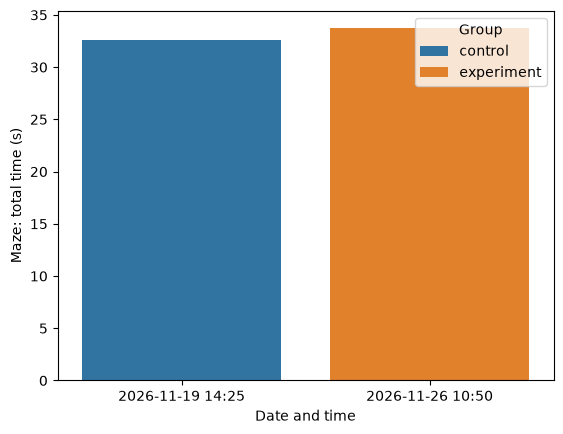

In [39]:
print(cognitive_p3['maze'])

sns.barplot(y=cognitive_p3['maze']['Maze: total time (s)'], x=cognitive_p3['maze']['Date and time'], hue=cognitive_p3['maze']['Group'])

### Memory

In [37]:
print(cognitive_p3['digit_span'])

        Group     Date and time  Digit span: longest correct sequence
1     control  2026-11-19 14:25                                     6
2  experiment  2026-11-26 10:50                                     7


In [36]:
print(cognitive_p3['corsi'])

        Group     Date and time  Corsi: longest correct sequence
1     control  2026-11-19 14:25                                9
2  experiment  2026-11-26 10:50                                7


### Inhibitory control

In [35]:
print(cognitive_p3['stroop'])

        Group     Date and time  Stroop: accuracy congruent (%)  \
1     control  2026-11-19 14:25                           100.0   
2  experiment  2026-11-26 10:50                           100.0   

   Stroop: accuracy incongruent (%)  \
1                             100.0   
2                              91.7   

   Stroop: mean RT congruent, correct trials (ms)  \
1                                           855.2   
2                                           649.4   

   Stroop: mean RT incongruent, correct trials (ms)  \
1                                             838.1   
2                                             714.0   

   Stroop: interference effect (ms)  
1                             -17.1  
2                              64.6  


In [34]:
print(cognitive_p3['go/no-go'])

        Group     Date and time  Go/No-Go: hit rate (%)  \
1     control  2026-11-19 14:25                     100   
2  experiment  2026-11-26 10:50                     100   

   Go/No-Go: false alarm rate (%)  Go/No-Go: mean RT hits (ms)  
1                              10                        293.6  
2                               0                        283.4  


In [33]:
print(cognitive_p3['flanker'])

        Group     Date and time  Flanker: accuracy congruent (%)  \
1     control  2026-11-19 14:25                              100   
2  experiment  2026-11-26 10:50                              100   

   Flanker: accuracy incongruent (%)  \
1                               83.3   
2                               91.7   

   Flanker: mean RT congruent, correct trials (ms)  \
1                                            414.5   
2                                            426.7   

   Flanker: mean RT incongruent, correct trials (ms)  \
1                                              490.3   
2                                              479.8   

   Flanker: interference effect (ms)  
1                               75.8  
2                               53.1  
